# Analisis Pengaruh Normalisasi Kata Tidak Baku terhadap Kinerja BM25
## pada Sistem Temu Kembali Informasi FAQ Praktik Industri JTIK FT UNM

**Stage 2 (Pertemuan 13): EDA, Text Preprocessing, dan Baseline**

Notebook ini mencakup:
1. Load & audit data
2. Exploratory Data Analysis (EDA)
3. Penanganan missing value / duplikasi / noise
4. Text preprocessing (regex + Sastrawi untuk Bahasa Indonesia)
5. Representasi teks (inverted index via BM25)
6. Split data (dev/test, stratified by gaya_kueri)
7. Baseline (BM25 tanpa normalisasi) + metrik awal


1. Load & Audit Data

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.max_colwidth", 120)

corpus = pd.read_csv("corpus_faq.csv")
queries = pd.read_csv("queries.csv")
kamus = pd.read_csv("kamus_normalisasi.csv")

print("corpus :", corpus.shape)
print("queries:", queries.shape)
print("kamus  :", kamus.shape)
corpus.head()


corpus : (40, 4)
queries: (665, 4)
kamus  : (73, 3)


,doc_id,pertanyaan_baku,jawaban,kategori
0,FAQ001,Bagaimana cara registrasi akun mahasiswa di SiPi?,"Mahasiswa klik Daftar Sekarang di halaman utama SiPi, lalu lengkapi NIM (sistem otomatis mengecek data), pilih Progr...",pendaftaran
1,FAQ002,"Akun SiPi saya belum terverifikasi atau email verifikasi tidak pernah masuk setelah registrasi, bagaimana solusinya?","Coba cek folder spam pada email yang didaftarkan. Jika tetap tidak ada, lakukan registrasi ulang dengan memastikan e...",pendaftaran
2,FAQ003,"Saya lupa password dan sudah reset tapi tetap tidak bisa login, bagaimana solusinya?","Gunakan fitur Lupa Password di halaman login, pastikan email yang digunakan adalah email aktif yang sama saat regist...",pendaftaran
3,FAQ004,"Saya salah memasukkan kelas atau program studi saat registrasi akun SiPi, apakah bisa diperbaiki tanpa membuat akun ...",Kesalahan input kelas atau program studi tidak bisa diedit sendiri oleh mahasiswa di profil. Hubungi admin untuk dik...,pendaftaran
4,FAQ005,Berapa minimal SKS yang harus ditempuh sebelum mengambil Praktik Industri?,Selama ini ketentuannya adalah 20 SKS mata kuliah ditambah 4 SKS PI.,kebijakan_akademik


In [2]:

queries.head()


,query_id,query_text,gaya_kueri,relevant_doc_id
0,Q0001,Bagaimana cara registrasi akun mahasiswa di SiPi?,formal,FAQ001
1,Q0002,cara daftar akun sipi gimana,informal,FAQ001
2,Q0003,cra bikin akun sipi mahasiswa,typo,FAQ001
3,Q0004,langkah-langkah membuat akun baru di sistem SiPi itu seperti apa,parafrase,FAQ001
4,Q0005,gmn daftar akun sipi min,singkatan,FAQ001


In [3]:

# audit tipe data & missing value
print("=== corpus ===")
print(corpus.dtypes)
print(corpus.isna().sum())
print("\n=== queries ===")
print(queries.dtypes)
print(queries.isna().sum())
print("\n=== kamus ===")
print(kamus.dtypes)
print(kamus.isna().sum())


=== corpus ===
doc_id             str
pertanyaan_baku    str
jawaban            str
kategori           str
dtype: object
doc_id             0
pertanyaan_baku    0
jawaban            0
kategori           0
dtype: int64

=== queries ===
query_id           str
query_text         str
gaya_kueri         str
relevant_doc_id    str
dtype: object
query_id           0
query_text         0
gaya_kueri         0
relevant_doc_id    0
dtype: int64

=== kamus ===
tidak_baku    str
baku          str
kategori      str
dtype: object
tidak_baku    0
baku          3
kategori      0
dtype: int64


In [4]:

# audit duplikasi
print("Duplikat corpus (doc_id):", corpus["doc_id"].duplicated().sum())
print("Duplikat query (query_id):", queries["query_id"].duplicated().sum())
print("Duplikat teks query per doc:",
      queries.duplicated(subset=["relevant_doc_id", "query_text"]).sum())

# audit referential integrity: relevant_doc_id harus ada di corpus
orphan = queries[~queries["relevant_doc_id"].isin(corpus["doc_id"])]
print("Query dengan relevant_doc_id tidak valid:", len(orphan))


Duplikat corpus (doc_id): 0
Duplikat query (query_id): 0
Duplikat teks query per doc: 0
Query dengan relevant_doc_id tidak valid: 0


**Catatan data dictionary singkat**

| Tabel | Kolom | Tipe | Deskripsi |
|---|---|---|---|
| corpus_final.csv | doc_id | str | ID unik FAQ (FAQ001-FAQ040) |
| | pertanyaan_baku | str | Pertanyaan baku representatif topik FAQ |
| | jawaban | str | Jawaban resmi (dari Panduan SiPi / respons admin di chat) |
| | kategori | str | Kategori topik (pendaftaran, dokumen, seminar, dst) |
| queries_final.csv | query_id | str | ID unik query |
| | query_text | str | Teks kueri (bervariasi gaya) |
| | gaya_kueri | str | formal / informal / singkatan / typo / parafrase |
| | relevant_doc_id | str | Ground truth -> doc_id di corpus (qrels biner) |
| kamus_final.csv | tidak_baku | str | Kata tidak baku/singkatan |
| | baku | str | Padanan baku (kosong utk partikel logat) |
| | kategori | str | singkatan / kontraksi / logat_makassar / dll |


2. Exploratory Data Analysis (EDA)

EDA berikut relevan dengan masalah penelitian: seberapa besar variasi gaya kueri,
seberapa "jauh" kueri tidak baku dari bentuk baku-nya, dan bagaimana sebaran
panjang dokumen/kueri yang akan memengaruhi performa BM25.

gaya_kueri
typo         160
informal     145
singkatan    142
parafrase    139
formal        79
Name: count, dtype: int64


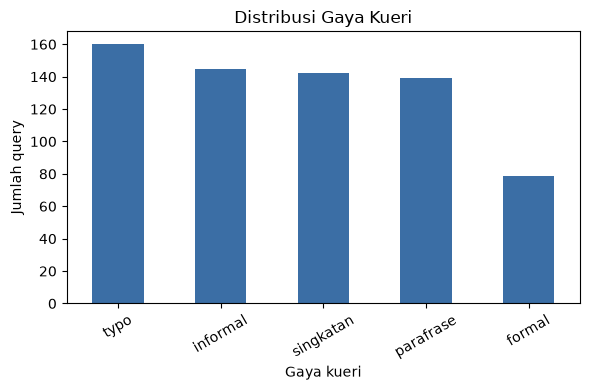

In [5]:

# 2.1 Distribusi gaya kueri
style_counts = queries["gaya_kueri"].value_counts()
print(style_counts)

plt.figure(figsize=(6,4))
style_counts.plot(kind="bar", color="#3b6ea5")
plt.title("Distribusi Gaya Kueri")
plt.ylabel("Jumlah query")
plt.xlabel("Gaya kueri")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("fig_distribusi_gaya_kueri.png", dpi=150)
plt.show()


count    40.000000
mean     16.625000
std       0.867874
min      14.000000
25%      16.000000
50%      17.000000
75%      17.000000
max      18.000000
Name: count, dtype: float64


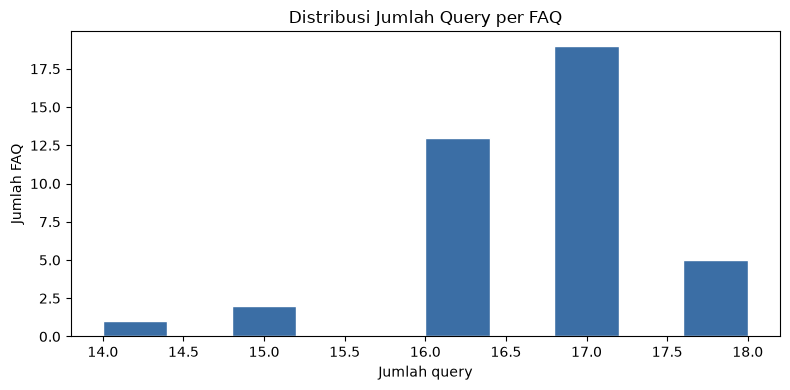

In [6]:

# 2.2 Distribusi jumlah query per FAQ (relevant_doc_id)
per_doc = queries["relevant_doc_id"].value_counts()
print(per_doc.describe())

plt.figure(figsize=(8,4))
plt.hist(per_doc.values, bins=10, color="#3b6ea5", edgecolor="white")
plt.title("Distribusi Jumlah Query per FAQ")
plt.xlabel("Jumlah query")
plt.ylabel("Jumlah FAQ")
plt.tight_layout()
plt.savefig("fig_distribusi_query_per_faq.png", dpi=150)
plt.show()


Panjang query (kata):
count    665.000000
mean      12.781955
std        3.581113
min        4.000000
25%       10.000000
50%       12.000000
75%       15.000000
max       23.000000
Name: panjang_kata, dtype: float64

Panjang jawaban FAQ (kata):
count    40.000000
mean     21.950000
std       7.958063
min       9.000000
25%      15.750000
50%      21.500000
75%      26.250000
max      38.000000
Name: panjang_jawaban, dtype: float64


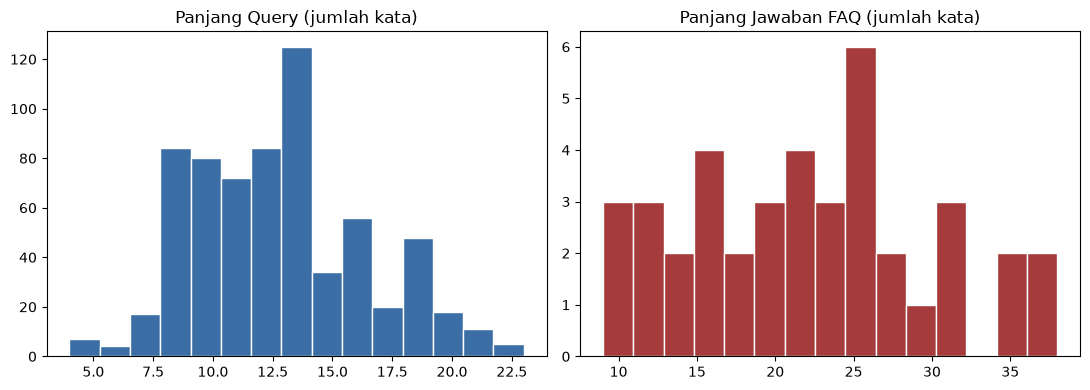

In [7]:

# 2.3 Panjang teks (jumlah kata) - query vs dokumen (pertanyaan_baku + jawaban)
queries["panjang_kata"] = queries["query_text"].str.split().apply(len)
corpus["panjang_pertanyaan"] = corpus["pertanyaan_baku"].str.split().apply(len)
corpus["panjang_jawaban"] = corpus["jawaban"].str.split().apply(len)

print("Panjang query (kata):")
print(queries["panjang_kata"].describe())
print("\nPanjang jawaban FAQ (kata):")
print(corpus["panjang_jawaban"].describe())

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].hist(queries["panjang_kata"], bins=15, color="#3b6ea5", edgecolor="white")
ax[0].set_title("Panjang Query (jumlah kata)")
ax[1].hist(corpus["panjang_jawaban"], bins=15, color="#a53b3b", edgecolor="white")
ax[1].set_title("Panjang Jawaban FAQ (jumlah kata)")
plt.tight_layout()
plt.savefig("fig_distribusi_panjang_teks.png", dpi=150)
plt.show()


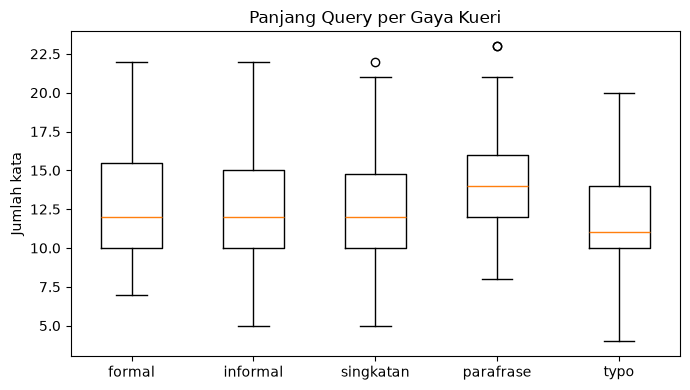

In [8]:

# 2.4 Panjang query per gaya kueri (boxplot) - cek apakah informal/typo
# cenderung lebih pendek/panjang dari formal
plt.figure(figsize=(7,4))
order = ["formal", "informal", "singkatan", "parafrase", "typo"]
data = [queries.loc[queries.gaya_kueri == g, "panjang_kata"] for g in order]
plt.boxplot(data, tick_labels=order)
plt.title("Panjang Query per Gaya Kueri")
plt.ylabel("Jumlah kata")
plt.tight_layout()
plt.savefig("fig_panjang_per_gaya.png", dpi=150)
plt.show()


[('pi', 333), ('apa', 245), ('di', 241), ('yang', 206), ('dan', 197), ('sipi', 164), ('atau', 107), ('cara', 100), ('dokumen', 98), ('saya', 94), ('bisa', 91), ('seminar', 90), ('surat', 86), ('info', 80), ('nilai', 75), ('pelaksanaan', 71), ('ia', 66), ('mahasiswa', 65), ('perlu', 65), ('ibu', 64)]


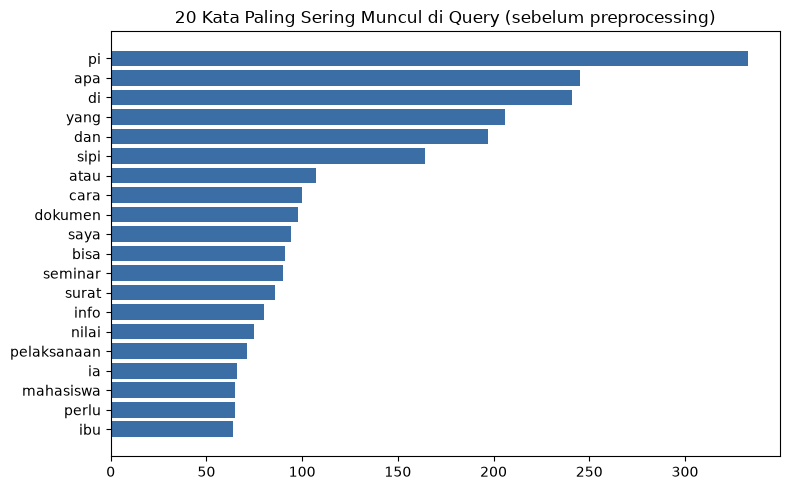

In [9]:

# 2.5 Frekuensi kata (sebelum preprocessing) - 20 kata paling sering muncul di query
all_words = " ".join(queries["query_text"]).lower()
all_words = re.sub(r"[^a-z\s]", " ", all_words)
word_freq = Counter(all_words.split())
top20 = word_freq.most_common(20)
print(top20)

plt.figure(figsize=(8,5))
words, counts = zip(*top20)
plt.barh(words[::-1], counts[::-1], color="#3b6ea5")
plt.title("20 Kata Paling Sering Muncul di Query (sebelum preprocessing)")
plt.tight_layout()
plt.savefig("fig_top20_kata_query.png", dpi=150)
plt.show()


In [10]:

# 2.6 Proporsi token di query yang termasuk kata tidak baku (ada di kamus)
kamus_set = set(kamus["tidak_baku"].str.lower())

def hitung_token_tidak_baku(text):
    tokens = re.sub(r"[^a-zA-Z\s]", " ", text.lower()).split()
    if not tokens:
        return 0.0
    hit = sum(1 for t in tokens if t in kamus_set)
    return hit / len(tokens)

queries["rasio_tdk_baku"] = queries["query_text"].apply(hitung_token_tidak_baku)
print(queries.groupby("gaya_kueri")["rasio_tdk_baku"].mean().sort_values(ascending=False))


gaya_kueri
singkatan    0.310627
informal     0.182781
typo         0.118281
formal       0.095874
parafrase    0.082682
Name: rasio_tdk_baku, dtype: float64


**Insight EDA awal (diisi ulang sesuai hasil run):**
- Gaya *typo* dan *singkatan* diharapkan punya rasio token "kata tidak baku" (sesuai kamus) tertinggi.
- Gaya *formal* diharapkan mendekati 0 (karena ditulis sesuai kamus/pertanyaan baku).
- Panjang query relatif pendek (khas pertanyaan FAQ chatbot), sementara jawaban FAQ jauh lebih panjang -> wajar untuk BM25 karena dokumen panjang perlu penyesuaian parameter `b` (length normalization).

3. Penanganan Missing Value, Duplikasi, dan Noise

Proses screening kualitas sudah dilakukan di tahap persiapan dataset (`finalize_dataset.py`):
duplikat exact dibuang, baris dengan `relevant_doc_id` tidak valid dibuang, dan kueri hasil
injeksi typo yang terdeteksi rusak (mis. kata kehilangan seluruh huruf vokal) ikut disaring.
Sel di bawah menunjukkan hasil audit akhir (seharusnya nol temuan).

In [11]:

print("Missing value corpus:", corpus.isna().sum().sum())
print("Missing value queries:", queries.isna().sum().sum())
print("Duplikat (doc_id, query_text):",
      queries.duplicated(subset=["relevant_doc_id", "query_text"]).sum())
print("Orphan relevant_doc_id:", (~queries.relevant_doc_id.isin(corpus.doc_id)).sum())
assert corpus.isna().sum().sum() == 0
assert queries.isna().sum().sum() == 0
assert (~queries.relevant_doc_id.isin(corpus.doc_id)).sum() == 0
print("OK - dataset bersih, siap diproses.")


Missing value corpus: 0
Missing value queries: 0
Duplikat (doc_id, query_text): 0
Orphan relevant_doc_id: 0
OK - dataset bersih, siap diproses.


4. Text Preprocessing

Pipeline preprocessing dirancang khusus untuk Bahasa Indonesia:
- Case folding: lowercase semua teks.
- Pembersihan regex: hapus tanda baca, karakter khusus, dan angka yang tidak relevan.
- Tokenisasi: split berbasis whitespace (regex) -- NLTK `word_tokenize` default
  dioptimalkan untuk Bahasa Inggris, sehingga untuk Bahasa Indonesia dipakai tokenizer
  regex sederhana yang konsisten dengan korpus campuran (baku + tidak baku).
- Stopword removal: menggunakan daftar stopword Sastrawi (Bahasa Indonesia),
  BUKAN stopword NLTK (yang untuk Bahasa Inggris).
- Stemming: menggunakan Sastrawi stemmer (bukan Porter/Snowball dari NLTK yang
  tidak didesain untuk morfologi Bahasa Indonesia).
- Preprocessing dijalankan 2 varian: tanpa normalisasi (baseline) dan
  dengan normalisasi kamus (dipakai di Eksperimen 1 & 3, bukan di notebook ini).

Alasan pemilihan Sastrawi dicantumkan karena library ini dirancang khusus untuk
morfologi afiksasi Bahasa Indonesia (imbuhan me-, pe-, -kan, -an, dst), yang tidak
bisa ditangani stemmer NLTK berbasis Bahasa Inggris (Porter/Snowball).

In [12]:

try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "--break-system-packages", "-q", "Sastrawi"])
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stemmer = StemmerFactory().create_stemmer()
stopword_remover = StopWordRemoverFactory()
stopwords_id = set(stopword_remover.get_stop_words())

print(f"Jumlah stopword Bahasa Indonesia (Sastrawi): {len(stopwords_id)}")
print(list(stopwords_id)[:15])


Jumlah stopword Bahasa Indonesia (Sastrawi): 123
['yakni', 'agar', 'lain', 'oleh', 'untuk', 'para', 'kenapa', 'seterusnya', 'dst', 'yang', 'dulunya', 'sekitar', 'serta', 'saya', 'seperti']


In [13]:

def case_fold(text):
    return text.lower()

def clean_regex(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text)   # buang tanda baca/simbol
    text = re.sub(r"\s+", " ", text).strip()     # rapikan spasi berlebih
    return text

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords_id]

def stem_tokens(tokens):
    # Sastrawi stem per-kata (cached agar cepat untuk korpus kecil ini)
    return [stemmer.stem(t) if t not in _stem_cache else _stem_cache[t] for t in tokens]

_stem_cache = {}
def stem_cached(token):
    if token not in _stem_cache:
        _stem_cache[token] = stemmer.stem(token)
    return _stem_cache[token]

def preprocess(text, do_stem=True, do_stopword=True):
    text = case_fold(text)
    text = clean_regex(text)
    tokens = tokenize(text)
    if do_stopword:
        tokens = remove_stopwords(tokens)
    if do_stem:
        tokens = [stem_cached(t) for t in tokens]
    return tokens

# contoh sebelum/sesudah
contoh = queries["query_text"].iloc[0]
print("SEBELUM :", contoh)
print("SESUDAH :", preprocess(contoh))


SEBELUM : Bagaimana cara registrasi akun mahasiswa di SiPi?
SESUDAH : ['bagaimana', 'cara', 'registrasi', 'akun', 'mahasiswa', 'sipi']


In [14]:

# jalankan preprocessing ke seluruh corpus (gabungan pertanyaan_baku + jawaban
# diindeks sebagai representasi dokumen) dan seluruh query (baseline: tanpa
# normalisasi kamus/levenshtein -- itu ranah Exp1-3)
corpus["teks_indeks"] = (corpus["pertanyaan_baku"] + " " + corpus["jawaban"])
corpus["tokens"] = corpus["teks_indeks"].apply(lambda t: preprocess(t))

queries["tokens_baseline"] = queries["query_text"].apply(lambda t: preprocess(t))

corpus[["doc_id", "tokens"]].head()


,doc_id,tokens
0,FAQ001,"[bagaimana, cara, registrasi, akun, mahasiswa, sipi, mahasiswa, klik, daftar, sekarang, halaman, utama, sipi, lalu, ..."
1,FAQ002,"[akun, sipi, verifikasi, email, verifikasi, pernah, masuk, registrasi, bagaimana, solusi, coba, cek, folder, spam, e..."
2,FAQ003,"[lupa, password, reset, tetap, login, bagaimana, solusi, guna, fitur, lupa, password, halaman, login, pasti, email, ..."
3,FAQ004,"[salah, masuk, kelas, program, studi, registrasi, akun, sipi, baik, buat, akun, baru, salah, input, kelas, program, ..."
4,FAQ005,"[berapa, minimal, sks, tempuh, ambil, praktik, industri, lama, tentu, 20, sks, mata, kuliah, tambah, 4, sks, pi]"


In [15]:

# dampak preprocessing terhadap ukuran vocabulary
vocab_sebelum = set(" ".join(corpus["teks_indeks"]).lower().split())
vocab_sesudah = set(w for toks in corpus["tokens"] for w in toks)
print(f"Vocabulary sebelum preprocessing : {len(vocab_sebelum)}")
print(f"Vocabulary sesudah preprocessing : {len(vocab_sesudah)}")
print(f"Pengurangan: {len(vocab_sebelum) - len(vocab_sesudah)} token "
      f"({(1 - len(vocab_sesudah)/len(vocab_sebelum))*100:.1f}%)")


Vocabulary sebelum preprocessing : 540
Vocabulary sesudah preprocessing : 290
Pengurangan: 250 token (46.3%)


5. Representasi Teks: Inverted Index via BM25

Representasi yang dipakai adalah **BM25 (Okapi BM25)**, bentuk pembobotan
probabilistik di atas inverted index -- bukan Boolean murni atau TF-IDF+cosine
biasa. Pemilihan BM25 beralasan karena penelitian ini memang mengukur *kinerja
BM25* terhadap normalisasi kata tidak baku (sesuai RQ1-RQ4), sehingga BM25
menjadi representasi inti, bukan sekadar baseline pembanding.

In [16]:
pip install rank-bm25

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
from rank_bm25 import BM25Okapi

corpus_tokens = corpus["tokens"].tolist()
doc_ids = corpus["doc_id"].tolist()

bm25 = BM25Okapi(corpus_tokens)  # parameter default k1=1.5, b=0.75 (akan di-tuning di Stage 3)
print(f"BM25 index dibangun dari {len(corpus_tokens)} dokumen.")
print(f"Rata-rata panjang dokumen: {bm25.avgdl:.1f} token")


BM25 index dibangun dari 40 dokumen.
Rata-rata panjang dokumen: 26.2 token


6. Split Data (Dev / Test)

Karena BM25 bukan model yang dilatih (tidak ada proses *fitting* parameter dari
data), tidak diperlukan train set. Yang diperlukan adalah **dev set** (untuk
tuning threshold Levenshtein & parameter BM25 di Stage 3) dan **test set**
(dilaporkan sekali di akhir). Split dilakukan:
- **stratified** berdasarkan `gaya_kueri` (supaya proporsi tiap gaya seimbang di dev & test)
- rasio dev:test = 25:75
- `random_state` tetap agar reproducible

In [18]:

from sklearn.model_selection import train_test_split

dev_df, test_df = train_test_split(
    queries,
    test_size=0.75,
    stratify=queries["gaya_kueri"],
    random_state=42,
)

print("Dev set :", dev_df.shape)
print("Test set:", test_df.shape)
print("\nProporsi gaya kueri - Dev:")
print(dev_df["gaya_kueri"].value_counts(normalize=True).round(3))
print("\nProporsi gaya kueri - Test:")
print(test_df["gaya_kueri"].value_counts(normalize=True).round(3))


Dev set : (166, 7)
Test set: (499, 7)

Proporsi gaya kueri - Dev:
gaya_kueri
typo         0.241
informal     0.217
parafrase    0.211
singkatan    0.211
formal       0.120
Name: proportion, dtype: float64

Proporsi gaya kueri - Test:
gaya_kueri
typo         0.240
informal     0.218
singkatan    0.214
parafrase    0.208
formal       0.118
Name: proportion, dtype: float64


In [19]:

# cek coverage: idealnya tiap FAQ terwakili minimal 1 query di test set
cov_test = set(test_df["relevant_doc_id"])
missing_in_test = set(corpus["doc_id"]) - cov_test
print(f"FAQ tanpa representasi di test set: {len(missing_in_test)}")
if missing_in_test:
    print(missing_in_test)

dev_df.to_csv("queries_dev.csv", index=False)
test_df.to_csv("queries_test.csv", index=False)
print("\nqueries_dev.csv & queries_test.csv tersimpan.")


FAQ tanpa representasi di test set: 0

queries_dev.csv & queries_test.csv tersimpan.


7. Baseline: BM25 Tanpa Normalisasi

Baseline sesuai rancangan eksperimen: BM25 dijalankan langsung pada query mentah
(hasil preprocessing standar, TANPA normalisasi kamus maupun koreksi Levenshtein).
Ini adalah titik pembanding untuk Exp1 (Dictionary), Exp2 (Levenshtein), dan
Exp3 (Dictionary+Levenshtein) di Stage 3.

In [20]:

def retrieve(query_tokens, topn=5):
    scores = bm25.get_scores(query_tokens)
    ranked_idx = np.argsort(scores)[::-1][:topn]
    return [(doc_ids[i], scores[i]) for i in ranked_idx]

def evaluate(df, bm25_index, doc_ids_list, threshold=None):
    hits_at_1 = 0
    reciprocal_ranks = []
    fallback_count = 0
    n = len(df)
    for _, row in df.iterrows():
        q_tokens = preprocess(row["query_text"])
        scores = bm25_index.get_scores(q_tokens)
        ranked_idx = np.argsort(scores)[::-1]
        ranked_docs = [doc_ids_list[i] for i in ranked_idx]
        top_score = scores[ranked_idx[0]]

        if threshold is not None and top_score < threshold:
            fallback_count += 1
            continue  # dianggap tidak menjawab -> tidak dihitung hit/MRR

        true_doc = row["relevant_doc_id"]
        if ranked_docs[0] == true_doc:
            hits_at_1 += 1
        if true_doc in ranked_docs:
            rank = ranked_docs.index(true_doc) + 1
            reciprocal_ranks.append(1 / rank)
        else:
            reciprocal_ranks.append(0)

    hit_at_1 = hits_at_1 / n
    mrr = np.mean(reciprocal_ranks)
    fallback_rate = fallback_count / n
    return {"Hit@1": hit_at_1, "MRR": mrr, "Fallback_Rate": fallback_rate, "n": n}


In [21]:

# evaluasi baseline di dev set (tanpa threshold dulu, threshold di-tuning Stage 3)
baseline_dev = evaluate(dev_df, bm25, doc_ids, threshold=None)
print("=== Baseline BM25 (tanpa normalisasi) - Dev set ===")
for k, v in baseline_dev.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")


=== Baseline BM25 (tanpa normalisasi) - Dev set ===
  Hit@1: 0.9398
  MRR: 0.9620
  Fallback_Rate: 0.0000
  n: 166


In [22]:

baseline_dev_per_gaya = {}
for gaya in order:
    subset = dev_df[dev_df["gaya_kueri"] == gaya]
    if len(subset) == 0:
        continue
    baseline_dev_per_gaya[gaya] = evaluate(subset, bm25, doc_ids, threshold=None)

res_df = pd.DataFrame(baseline_dev_per_gaya).T
print("=== Baseline BM25 per gaya kueri (Dev set) ===")
res_df


=== Baseline BM25 per gaya kueri (Dev set) ===


,Hit@1,MRR,Fallback_Rate,n
formal,1.000000,1.000000,0.0,20.0
informal,0.972222,0.986111,0.0,36.0
singkatan,0.914286,0.947619,0.0,35.0
parafrase,0.971429,0.985714,0.0,35.0
typo,0.875000,0.913194,0.0,40.0


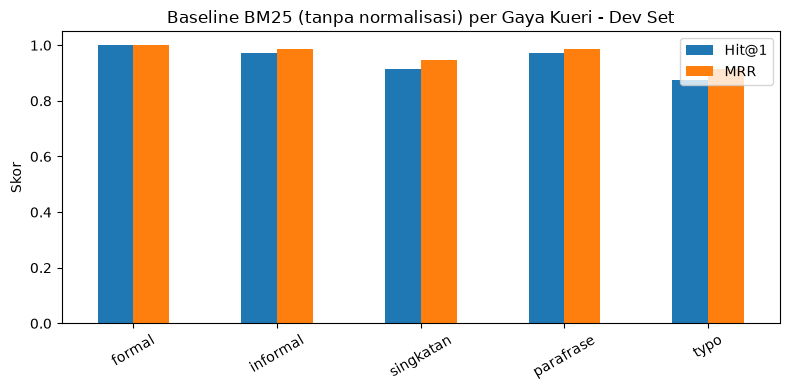

In [23]:

plt.figure(figsize=(8,4))
res_df[["Hit@1", "MRR"]].plot(kind="bar", ax=plt.gca())
plt.title("Baseline BM25 (tanpa normalisasi) per Gaya Kueri - Dev Set")
plt.ylabel("Skor")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("fig_baseline_per_gaya.png", dpi=150)
plt.show()
